# Sprint 5 — Validación con datos no vistos e impacto en matrículas
**Entregable de la Semana 5:** *tomar un pequeño grupo de datos que el modelo no haya visto antes y evaluar si
acierta o falla*, con *un cálculo estimado de cómo esto ayuda a la Universidad a no perder dinero o estudiantes*.
Además, simular escenarios que muestren cómo el modelo optimiza la captación y la asignación de recursos.

| Sección | Contenido |
|---|---|
| 1 | Se abre el resultado sellado de la campaña 2027-1 |
| 2 | ¿Acierta o falla? |
| 3 | Escenario 1: ¿a quién llamar primero? |
| 4 | Escenario 2: Expo Estudiantes |
| 5 | Sensibilidad de los supuestos y acciones por segmento |

In [1]:
import sys
import warnings
from pathlib import Path

# Raíz del repositorio: se sube de carpeta hasta encontrar config/reglas_negocio.yaml
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "reglas_negocio.yaml").exists())
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore")
EN_COLAB = False
SPRINTS = RAIZ / "sprints"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#1B365D", "#E07B39", "#9AA5B1"

In [3]:
import caracteristicas as ca
import flujo
import modelado as mo

# Lee las tablas planas por la API de Supabase (solo lectura): dataset_matricula y las respuestas de la entrevista
# (dataset_entrevista). Sin clave de Supabase usa la copia de esas tablas: en el computador, la del repositorio; en
# Colab, la que está en GitHub (no hay que subir nada). Después construye las columnas del Sprint 2 (con el puntaje NLP).
f = flujo.cargar_y_construir("auto")
d, ref, cfg = f["inscritos"], f["referencias"], ca.configuracion()
print("Origen de los datos:", f["origen"])
print(f"Inscritos: {len(d):,} · con entrevista: {int(d['entrevista_realizada'].sum()):,}")
print(d["particion"].value_counts().to_string())

Origen de los datos: Supabase (API de solo lectura)
Inscritos: 2,991 · con entrevista: 2,524
particion
ENTRENAMIENTO    1310
PRUEBA            761
VALIDACION        504
CAMPANA           416


In [4]:
# Hiperparámetros elegidos en el Sprint 3 (sprints/sprint_3_modelado/modelos/*.json)
PARAMETROS_FINALES = {'matricula': {'parametros': {'C': 0.1, 'l1_ratio': 0.0, 'solver': 'saga'}, 'tipo': 'logistica'},
 'xgboost': {'parametros': {'learning_rate': 0.03,
                            'max_depth': 2,
                            'min_child_weight': 5,
                            'n_estimators': 200}}}

import joblib

MOD = SPRINTS / "sprint_3_modelado" / "modelos"
ruta_fondo = SPRINTS / "sprint_4_explicabilidad" / "resultados" / "fondo_shap.joblib"
fondos = joblib.load(ruta_fondo) if ruta_fondo.exists() else {}
art = {"referencias": ref,
       "modelo_matricula": joblib.load(MOD / "modelo_matricula.joblib")["modelo"],
       "modelo_matricula_xgboost": joblib.load(MOD / "modelo_matricula_xgboost.joblib")["modelo"],
       "logistica_sprint2": joblib.load(MOD / "logistica_sprint2_matricula.joblib")["modelo"]}
hist = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION", "PRUEBA")
art["fondo_matricula"] = fondos.get("fondo_matricula", mo.preparar_X(hist, ref, mo.VARIABLES_MATRICULA_NLP).sample(300, random_state=1))
print("Modelos del Sprint 3 cargados:", ", ".join(k for k in art if k.startswith(("modelo", "logistica"))))

Modelos del Sprint 3 cargados: modelo_matricula, modelo_matricula_xgboost, logistica_sprint2


## 1. Se abre el "sobre sellado"
Desde la Semana 1, el resultado de matrícula de los inscritos de la campaña 2027-1 quedó guardado aparte y **no se usó**
para entrenar, ajustar ni elegir modelos. Ahora se lee de Supabase (tabla `resultado_campana_2027_1`, solo lectura);
sin clave de Supabase, de su copia en el repositorio (en Colab, la de GitHub).

> Aclaración honesta: es un resultado **sintético**, generado con las mismas reglas que el resto de la base. Con datos
> reales de Admisiones, este mismo cuaderno se vuelve a ejecutar.

In [5]:
import datos
import impacto as im
sellado, origen = datos.cargar("resultado_campana_2027_1", "auto")   # Supabase, o su copia (repositorio o GitHub)
camp = flujo.conjunto(d, "CAMPANA").merge(sellado, on="inscripcion_id", how="left", validate="one_to_one")
print(f"Resultado 2027-1 leído de: {origen} · {len(camp)} inscritos · se matricularon {int(camp['matriculado_real'].sum())}")

Resultado 2027-1 leído de: Supabase (API de solo lectura) · 416 inscritos · se matricularon 246


## 2. ¿Acierta o falla?

,n,error_pct,auc_roc,brier,precision,recall
Modelo elegido (regresión logística con NLP),416.000,33.894,0.697,0.213,0.685,0.789
XGBoost,416.000,34.135,0.687,0.216,0.696,0.752
Regresión logística (Sprint 2),416.000,35.337,0.665,0.222,0.671,0.789


Error del modelo elegido: 33.9% (IC 95%: 29.6% a 38.7%)
Diferencia con la logística del Sprint 2: IC 95% de -4.1 a 1.2 puntos (incluye el 0: rinden igual).


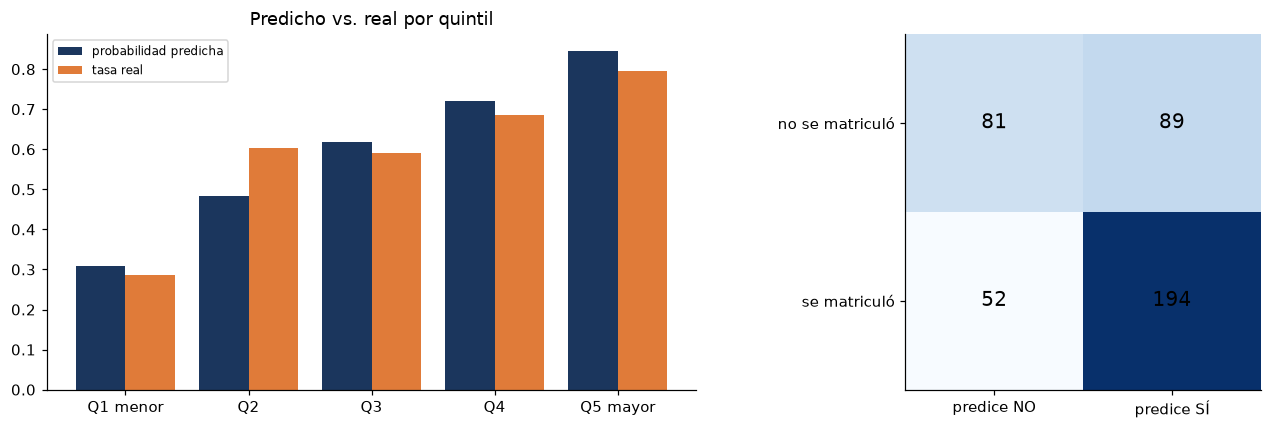

,inscritos,prob_media,tasa_real
grupo,,,
Q1 menor,84,0.309,0.286
Q2,83,0.484,0.602
Q3,83,0.618,0.590
Q4,83,0.720,0.687
Q5 mayor,83,0.845,0.795


In [6]:
from sklearn.metrics import confusion_matrix, roc_auc_score
V, V2 = mo.VARIABLES_MATRICULA_NLP, mo.VARIABLES_MATRICULA   # elegido y XGBoost con NLP · Sprint 2 sin NLP
Xc, Xc2, yc = mo.preparar_X(camp, ref, V), mo.preparar_X(camp, ref, V2), camp["matriculado_real"].astype(int)
hist = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION", "PRUEBA")
probs = {"Modelo elegido (regresión logística con NLP)": art["modelo_matricula"].predict_proba(Xc)[:, 1],
         "XGBoost": art["modelo_matricula_xgboost"].predict_proba(Xc)[:, 1],
         "Regresión logística (Sprint 2)": art["logistica_sprint2"].predict_proba(Xc2)[:, 1]}
res = {n: mo.metricas(yc, q) for n, q in probs.items()}
display(mo.tabla_metricas(res)[["n", "error_pct", "auc_roc", "brier", "precision", "recall"]])
p_final = probs["Modelo elegido (regresión logística con NLP)"]
ic = mo.intervalo_bootstrap(yc, p_final, lambda a, q, u: 100 * ((q >= u) != a).mean())
print(f"Error del modelo elegido: {res['Modelo elegido (regresión logística con NLP)']['error_pct']:.1f}% (IC 95%: {ic[0]:.1f}% a {ic[1]:.1f}%)")
dif = mo.diferencia_error(yc, probs["Regresión logística (Sprint 2)"], p_final)
print(f"Diferencia con la logística del Sprint 2: IC 95% de {dif[0]:.1f} a {dif[1]:.1f} puntos"
      + (" (incluye el 0: rinden igual)." if dif[0] <= 0 <= dif[1] else "."))
camp["prob"] = p_final
q = camp.assign(grupo=pd.qcut(camp["prob"].rank(method="first"), 5, labels=["Q1 menor", "Q2", "Q3", "Q4", "Q5 mayor"])) \
        .groupby("grupo", observed=True).agg(inscritos=("prob", "size"), prob_media=("prob", "mean"), tasa_real=("matriculado_real", "mean"))
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(q))
ejes[0].bar(x - 0.2, q["prob_media"], 0.4, color=AZUL, label="probabilidad predicha")
ejes[0].bar(x + 0.2, q["tasa_real"], 0.4, color=NARANJA, label="tasa real")
ejes[0].set_xticks(x, q.index); ejes[0].legend(fontsize=8); ejes[0].set_title("Predicho vs. real por quintil")
cm = confusion_matrix(yc, p_final >= 0.5); ejes[1].imshow(cm, cmap="Blues")
for (i, j), val in np.ndenumerate(cm):
    ejes[1].text(j, i, val, ha="center", va="center", fontsize=13)
ejes[1].set_xticks([0, 1], ["predice NO", "predice SÍ"]); ejes[1].set_yticks([0, 1], ["no se matriculó", "se matriculó"])
plt.tight_layout(); plt.show()
display(q.round(3))

**Lectura.** El modelo falla en cerca de 1 de cada 3 casos individuales, pero **ordena**: el quintil de mayor
probabilidad se matricula más del doble que el de menor. Para la Universidad, lo valioso es saber **a quién
dedicarle el esfuerzo**, no adivinar a cada persona.

## 3. Escenario 1: ¿a quién llamar primero?
Los asesores solo alcanzan a hacer seguimiento intensivo al 30% de los inscritos (supuesto). La llamada ayuda poco
a quien ya decidió y más al indeciso (supuesto):

`efecto(p) = 0,10 × 4 × p × (1 − p)`, es decir, +10 puntos si p = 0,5 y casi 0 si p está cerca de 0 o de 1.

Valor de una matrícula adicional = precio neto del 1er semestre con su beca (tarifas oficiales). No se calculan costos
porque no hay datos de cuánto cuesta el seguimiento.

In [7]:
s = cfg["impacto"]["seguimiento"]
e1 = im.escenario_seguimiento(camp["prob"], camp["valor_neto_primer_semestre"], s["capacidad_pct"], s["efecto_maximo"])
display(e1.round(1))
print(f"Llamar a los indecisos (modelo) deja {e1.iloc[2]['matriculas_adicionales'] - e1.iloc[0]['matriculas_adicionales']:.1f} matrículas y "
      f"${e1.iloc[2]['ingreso_primer_semestre_cop'] - e1.iloc[0]['ingreso_primer_semestre_cop']:,.0f} ".replace(",", ".")
      + "más que llamar al azar en una campaña; llamar primero a los de mayor probabilidad es lo peor.")

,estrategia,inscritos_con_seguimiento,matriculas_adicionales,ingreso_primer_semestre_cop
0,Al azar (sin modelo),125,10.200,"42,090,888.600"
1,Mayor probabilidad primero,125,7.500,"25,659,015.100"
2,Indecisos primero (modelo),125,12.300,"53,315,204.000"


Llamar a los indecisos (modelo) deja 2.1 matrículas y $11.224.315 más que llamar al azar en una campaña; llamar primero a los de mayor probabilidad es lo peor.


## 4. Escenario 2: Expo Estudiantes
Se aplica el mismo seguimiento priorizado a los inscritos que llegaron por la Expo en cada campaña histórica y se mide
cuántas **matrículas más** se esperan. No se calcula el costo por matriculado porque no hay datos de la inversión en el
evento.

In [8]:
expo = hist[hist["canal"] == "EXPOESTUDIANTES"].copy()
expo["prob"] = art["modelo_matricula"].predict_proba(mo.preparar_X(expo, ref, V))[:, 1]
filas = []
for per, g in expo.groupby("periodo"):
    reales = int(g["matriculado"].astype(int).sum())
    t = im.escenario_seguimiento(g["prob"], g["valor_neto_primer_semestre"], s["capacidad_pct"], s["efecto_maximo"])
    filas.append({"campaña": per, "inscritos Expo": len(g), "matriculados": reales,
                  "matrículas adicionales": t.iloc[2]["matriculas_adicionales"]})
display(pd.DataFrame(filas).round(1))
seg = expo.assign(m=expo["matriculado"].astype(float)).groupby("segmento_mercado").agg(inscritos=("m", "size"), tasa=("m", "mean"))
print("Segmentos que mejor convierten cuando llegan por la Expo:")
display(seg.sort_values("tasa", ascending=False).round(3))

,campaña,inscritos Expo,matriculados,matrículas adicionales
0,2024-1,44,17,1.300
1,2025-1,60,26,1.800
2,2026-1,74,30,2.200


Segmentos que mejor convierten cuando llegan por la Expo:


,inscritos,tasa
segmento_mercado,,
"S1: Colegio privado, estrato más alto",64,0.516
"S2: Colegio público, viven cerca del campus",57,0.386
"S4: Aspirantes mayores, puntaje ICFES bajo",15,0.333
"S3: Viven lejos del campus, estrato más bajo",42,0.310


## 5. Sensibilidad y acciones por segmento
Cada supuesto se mueve −50% y +50%, dejando los demás fijos, para ver cuánto cambia el resultado (gráfico de tornado).
El supuesto que más mueve la cifra es el que primero hay que validar con Admisiones.

In [9]:
def matriculas_seguimiento(capacidad_pct, efecto_maximo):
    t = im.escenario_seguimiento(camp["prob"], camp["valor_neto_primer_semestre"], capacidad_pct, efecto_maximo)
    return {"matriculas_con_modelo": float(t.iloc[2]["matriculas_adicionales"])}
sens1 = im.sensibilidad(matriculas_seguimiento, dict(s), list(s), "matriculas_con_modelo")
display(sens1.round(2))
acciones = im.acciones_por_segmento(camp, camp["prob"], cfg["modelado"]["segmentos_propension"])
display(acciones.round(3))

,supuesto,valor_base,resultado_bajo,resultado_base,resultado_alto,rango
0,efecto_maximo,0.100,6.150,12.290,18.440,12.290
1,capacidad_pct,0.300,6.170,12.290,18.080,11.910


,inscritos,propension_media,pct_indecisos,pct_lejos,pct_con_beca,valor_esperado_por_inscrito,accion_sugerida
segmento_mercado,,,,,,,
"S4: Aspirantes mayores, puntaje ICFES bajo",35,0.620,0.457,0.286,0.457,"2,475,204.204",asegurar: proceso de matrícula ágil y recordat...
"S1: Colegio privado, estrato más alto",152,0.636,0.296,0.112,0.599,"2,391,215.412",asegurar: proceso de matrícula ágil y recordat...
"S2: Colegio público, viven cerca del campus",132,0.595,0.348,0.000,0.545,"2,279,139.783",asegurar: proceso de matrícula ágil y recordat...
"S3: Viven lejos del campus, estrato más bajo",97,0.520,0.392,0.887,0.412,"2,120,790.398",asegurar: proceso de matrícula ágil y recordat...


## Conclusiones del Sprint 5
1. Con datos que nunca vio, el modelo **ordena** a los inscritos mucho mejor que el azar (AUC cercano a 0,68). Su error
   individual (cerca de 34%) es unos 3 puntos menor que el de la regresión logística del Sprint 2, pero la diferencia
   todavía cabe en el margen del azar.
2. **Captación:** priorizar a los indecisos da más matrículas e ingreso que llamar al azar, y mucho más que llamar a los
   seguros. En la Expo se esperan algunas matrículas más con el mismo seguimiento.
3. Las cifras dependen de dos supuestos (capacidad de seguimiento y efecto de la llamada). El análisis de sensibilidad
   muestra cuál validar primero. No se incluyen costos porque no hay datos de ellos.